### 1. Setup and loading

In [28]:
import sys                    
sys.path.append("..")           

import numpy as np               
import pandas as pd              
import matplotlib.pyplot as plt  

from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet   # regression models
from sklearn.ensemble import HistGradientBoostingRegressor  # boosting (class "Bagged Trees and Random Forests")
from sklearn.model_selection import cross_val_score, PredefinedSplit, RandomizedSearchCV   # cross-validation with our saved folds
from sklearn.pipeline import Pipeline   # preprocessing + model in one object
from sklearn.metrics import roc_auc_score   # ranking quality (class "Classification Metrics")

from src.utils import SEED, load_data, select_by_quota, recall_at_quota, within_village_auc   # shared group code
from src.features import SET_B, without_village_level, make_preprocessor  # shared feature lists + preprocessing
from src.features import skewed, other_numeric, binary    # which column gets which treatment

print("SEED:", SEED)   # check that the shared seed is loaded (should be 40)

train, test = load_data()   # training villages (with their fold) and test villages, made in 01_data_prep


SEED: 40


### 2. Features (X) and target (y)

In [ ]:
# Features: set B without the village-level columns
features = without_village_level(SET_B)   
target = "LOGCONSUMPTION"                 # what we predict

print("number of features:", len(features)) 
print(features)

number of features: 92
['pcfloor', 'tfloor', 'twall', 'troof', 'toilet', 'water', 'lighting', 'fcook', 'house', 'hhsize', 'hhsize2', 'age04', 'eschild', 'jschild', 'sschild', 'depratio', 'hhage', 'hhage2', 'hhmale', 'hhmarried', 'hhmalemarr', 'hheduc2', 'hheduc3', 'hheduc4', 'hhsector1', 'hhsector2', 'hhsector3', 'formal', 'informal', 'higheduc2', 'higheduc3', 'higheduc4', 'credit', 'se2_17', 'se2_11_12', 'se2_125', 'se2_126_127', 'se2_119', 'se2_117', 'se2_115', 'se2_13_15', 'se2_14', 'se2_114', 'se2_18', 'se2_124', 'se2_122_123', 'se5_110', 'se5_11_12', 'se5_15_16', 'se2_138', 'hheduc_missing', 'no_workingage', 'pcfloor_missing', 'se2_16', 'se2_111', 'se2_110', 'se2_118', 'se2_112', 'se2_121', 'se2_132_133', 'se2_128', 'se2_129', 'se5_17', 'se5_13', 'se2_139', 'FLOORTOPQUALITY', 'hr0609', 'hr0610', 'hr0611', 'hr0612', 'hr0613', 'hr0614', 'hr0615', 'hr0616', 'hr0617', 'hr0618', 'hr0619', 'hr0620', 'hr0621', 'hr0622', 'hr0623', 'hr0625', 'hr0626', 'hr0627', 'hr0628', 'hr0629', 'hr0630'

In [30]:
# Train and test villages
print("train:", train.shape, "| villages:", train["hhea"].nunique())   # rows, columns, villages
print("test: ", test.shape, "| villages:", test["hhea"].nunique())
print("no village in both:", set(train["hhea"]).isdisjoint(test["hhea"]))   # must be True

train: (4090, 113) | villages: 512
test:  (1023, 112) | villages: 128
no village in both: True


In [31]:
# Features (X) and target (y) for training 
X_train = train[features].astype(float)   # features as decimal numbers (<NA> becomes NaN, filled later in the pipeline)
y_train = train[target]     # target for training

print("X_train:", X_train.shape, "| y_train:", y_train.shape)   # rows, columns

na = X_train.isna().sum()     # missing values per column (train)
print(na[na > 0])        # only columns with missing values
print("households with a missing value:", X_train.isna().any(axis=1).mean().round(3))   # True/False per row, then the share

X_train: (4090, 92) | y_train: (4090,)
pcfloor         42
toilet           7
water            1
depratio       177
hhage            4
hhage2           4
se2_122_123      4
se5_110          1
se2_112          1
se2_121          1
se5_17           1
se2_139         10
hr0623           1
hr0627          46
hr0628           2
hr0629           2
hr0634           1
hr0635           1
dtype: int64
households with a missing value: 0.07


### 3. Missing values: fill with the training median 

In [32]:
# Which columns get which treatment in make_preprocessor (src/features.py)
print("skewed numbers (median fill, then Yeo-Johnson):", skewed(features))
print("other numbers (median fill):                    ", other_numeric(features))
print("0/1 columns (most frequent value):              ", len(binary(features)), "columns")

skewed numbers (median fill, then Yeo-Johnson): ['pcfloor', 'eschild', 'depratio', 'hr0612', 'hr0614', 'hr0615', 'hr0619', 'hr0621', 'hr0623', 'hr0627', 'hr0628']
other numbers (median fill):                     ['hhsize', 'hhsize2', 'age04', 'jschild', 'sschild', 'hhage', 'hhage2', 'hr0609', 'hr0610', 'hr0611', 'hr0613', 'hr0616', 'hr0617', 'hr0618', 'hr0620', 'hr0622', 'hr0625', 'hr0626', 'hr0629', 'hr0630', 'hr0631', 'hr0632', 'hr0633', 'hr0634', 'hr0635']
0/1 columns (most frequent value):               56 columns


### 4. Scaling

In [33]:
# Preprocessing 
prep = make_preprocessor(features)   # median fill + Yeo-Johnson + scaling
X_train_prep = pd.DataFrame(prep.fit_transform(X_train),    # learned on the training data only
                            columns=prep.get_feature_names_out())    # column names after preprocessing

cols = ["pcfloor", "hhsize", "hhage2", "toilet"]                  
print("train before preprocessing:")
display(X_train[cols].agg(["mean", "std"]).round(2))               
print("train after preprocessing:")
display(X_train_prep[cols].agg(["mean", "std"]).round(2))          
print("missing values left:", X_train_prep.isna().sum().sum())     

train before preprocessing:


,pcfloor,hhsize,hhage2,toilet
mean,24.60,4.35,2499.37,0.65
std,29.19,1.94,1484.73,0.48


train after preprocessing:


,pcfloor,hhsize,hhage2,toilet
mean,-0.0,-0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0


missing values left: 0


### 5. OLS (linear regression without penalty)

In [34]:
# Cross-validation folds: the saved village folds from 01_data_prep
cv = PredefinedSplit(train["fold"])  

print("number of folds:", cv.get_n_splits())   
for k, (train_idx, val_idx) in enumerate(cv.split()):  # check each round
    print(f"round {k}: train {len(train_idx)} | validation {len(val_idx)}")

number of folds: 5
round 0: train 3268 | validation 822
round 1: train 3268 | validation 822
round 2: train 3275 | validation 815
round 3: train 3275 | validation 815
round 4: train 3274 | validation 816


In [35]:
# Cross-validation error of OLS
ols = Pipeline([
    ("prep", make_preprocessor(features, drop_first=True)),   # fill + Yeo-Johnson + scale (drop_first only matters for district dummies, and there are none here)
    ("model", LinearRegression()),   # OLS model, no penalty
])
cv_score = cross_val_score(ols, X_train, y_train, cv=cv,
                           scoring="neg_mean_squared_error")  # preprocessing is learned again in every round
ols_cv_mse = -np.mean(cv_score)      # flip the sign, average over the 5 folds

print("MSE per fold:", (-cv_score).round(4))  # error in each validation fold
print(f"OLS CV MSE:  {ols_cv_mse:.4f}")                       
print(f"OLS CV RMSE: {np.sqrt(ols_cv_mse):.4f}")               
print(f"MSE if we always guess the mean: {y_train.var():.4f}")
print(f"R2 = 1 - MSE / variance: {1 - ols_cv_mse / y_train.var():.2f}")  # share of the variation that OLS explains

MSE per fold: [0.2296 0.2031 0.2369 0.2369 0.211 ]
OLS CV MSE:  0.2235
OLS CV RMSE: 0.4728
MSE if we always guess the mean: 0.4549
R2 = 1 - MSE / variance: 0.51


In [36]:
# Fit OLS on all training households and look at the coefficients
ols.fit(X_train, y_train)      # preprocessing + OLS, learned on all training data
names = ols.named_steps["prep"].get_feature_names_out()    # column names after preprocessing
ols_coefs = pd.Series(ols.named_steps["model"].coef_, index=names)   # coefficients with the right names

print(f"intercept: {ols.named_steps['model'].intercept_:.3f}")  # prediction for an average household
print(f"mean of y_train: {y_train.mean():.3f}")               
top = ols_coefs.abs().sort_values(ascending=False).index[:10]   # names of the 10 largest coefficients (by size)
display(ols_coefs.loc[top].round(3))                            

intercept: 6.062
mean of y_train: 6.062


hhsize        -0.617
hhsize2        0.350
hr0619         0.165
hr0627         0.110
se2_132_133    0.082
se2_122_123   -0.077
hr0616         0.077
se2_118        0.073
se2_128        0.071
hr0633        -0.069
dtype: float64

**Result:**

OLS has a CV MSE of 0.224. If we always guess the mean, the MSE is 0.455. So R² ≈ 0.51: the features explain about half of the differences in log consumption between households (set A: 0.49).

The intercept (6.062) is the same as the mean of y_train, because all features are scaled to mean 0. So it is the prediction for an average household.

The largest coefficient is again hhsize (-0.62): bigger households have lower consumption per person. hhsize2 is positive (0.35), so this effect gets weaker for very big households. The next largest coefficients are new set B features: the number of mobile phones (hr0619, 0.17), jewelry (hr0627, 0.11) and the number of DVD players (hr0616, 0.08). Because the features are scaled, each coefficient is the effect of one standard deviation more of that feature.

Some set B features measure almost the same thing as others, and OLS then gives them opposite signs. Owning a rice husker (se2_132_133) gets +0.08, but the number of rice huskers (hr0633) gets -0.07. Owning jewelry (se2_122_123) gets -0.08, but jewelry (hr0627) gets +0.11. The two coefficients of such a pair partly cancel each other, so we cannot read them one by one. Ridge and Lasso can help with this (section 6).

### 6. Ridge and Lasso

In [37]:
# Penalty strengths to try
alphas_ridge = np.logspace(-3, 3, 20)   # Ridge: 20 values from 0.001 to 1000, evenly spread on a log scale
alphas_lasso = np.logspace(-4, 0, 20)   # Lasso: 20 values from 0.0001 to 1

print(f"Ridge: {len(alphas_ridge)} values from {alphas_ridge.min()} to {alphas_ridge.max()}")
print(f"Lasso: {len(alphas_lasso)} values from {alphas_lasso.min()} to {alphas_lasso.max()}")

Ridge: 20 values from 0.001 to 1000.0
Lasso: 20 values from 0.0001 to 1.0


In [38]:
# Ridge: CV error for every alpha
ridge_scores = []      # CV MSE for each alpha
for alpha in alphas_ridge:    # try each alpha
    ridge_model = Pipeline([
        ("prep", make_preprocessor(features)),              
        ("model", Ridge(alpha=alpha)),   # Ridge with this penalty
    ])
    cv_score = cross_val_score(ridge_model, X_train, y_train, cv=cv,
                               scoring="neg_mean_squared_error")  
    ridge_scores.append(-np.mean(cv_score))    # flip the sign, save the average MSE

best_alpha_ridge = alphas_ridge[np.argmin(ridge_scores)]     # alpha with the lowest CV error
best_score_ridge = np.min(ridge_scores)   

print(f"Best alpha: {best_alpha_ridge:.3f}")
print(f"Ridge CV MSE: {best_score_ridge:.5f} | OLS CV MSE: {ols_cv_mse:.5f}")

Best alpha: 12.743
Ridge CV MSE: 0.22275 | OLS CV MSE: 0.22349


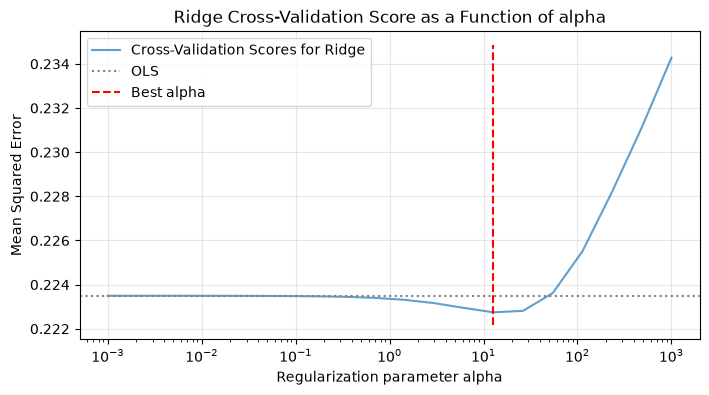

In [39]:
# Plot: Ridge CV error for each alpha
fig, ax = plt.subplots(figsize=(8, 4))

# CV error for each alpha that was tried
ax.plot(alphas_ridge, ridge_scores,alpha=0.7, label="Cross-Validation Scores for Ridge")
# OLS for comparison
ax.axhline(ols_cv_mse, color="grey", linestyle=":", label="OLS")
# The chosen alpha
ax.vlines(best_alpha_ridge, ax.get_ylim()[0], ax.get_ylim()[1], linestyle="--", color="red", label="Best alpha")

# Aesthetics
ax.set_xscale("log")  # alphas are spread on a log scale
ax.set_xlabel("Regularization parameter alpha")
ax.set_ylabel("Mean Squared Error")
ax.set_title("Ridge Cross-Validation Score as a Function of alpha")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

In [40]:
# Fit Ridge with the best alpha on all training households
ridge = Pipeline([
    ("prep", make_preprocessor(features)),                  
    ("model", Ridge(alpha=best_alpha_ridge)),   # Ridge with the chosen penalty
])
ridge.fit(X_train, y_train)                                 
ridge_coefs = pd.Series(ridge.named_steps["model"].coef_,
                        index=ridge.named_steps["prep"].get_feature_names_out())   

compare = pd.DataFrame({"OLS": ols_coefs, "Ridge": ridge_coefs})   
display(compare.loc[top].round(3))  

,OLS,Ridge
hhsize,-0.617,-0.557
hhsize2,0.350,0.301
hr0619,0.165,0.158
hr0627,0.110,0.107
se2_132_133,0.082,0.070
se2_122_123,-0.077,-0.074
hr0616,0.077,0.076
se2_118,0.073,0.054
se2_128,0.071,0.068
hr0633,-0.069,-0.057


In [41]:
# Lasso: CV error for every alpha
lasso_scores = []      
for alpha in alphas_lasso:    
    lasso_model = Pipeline([
        ("prep", make_preprocessor(features)),              
        ("model", Lasso(alpha=alpha, max_iter=10000)),      
    ])
    cv_score = cross_val_score(lasso_model, X_train, y_train, cv=cv,
                               scoring="neg_mean_squared_error")   # same village folds as OLS and Ridge
    lasso_scores.append(-np.mean(cv_score))                  

best_alpha_lasso = alphas_lasso[np.argmin(lasso_scores)]     # alpha with the lowest CV error
best_score_lasso = np.min(lasso_scores)                     

print(f"Best alpha: {best_alpha_lasso:.4f}")
print(f"Lasso CV MSE: {best_score_lasso:.5f} | OLS CV MSE: {ols_cv_mse:.5f}")

Best alpha: 0.0018
Lasso CV MSE: 0.22182 | OLS CV MSE: 0.22349


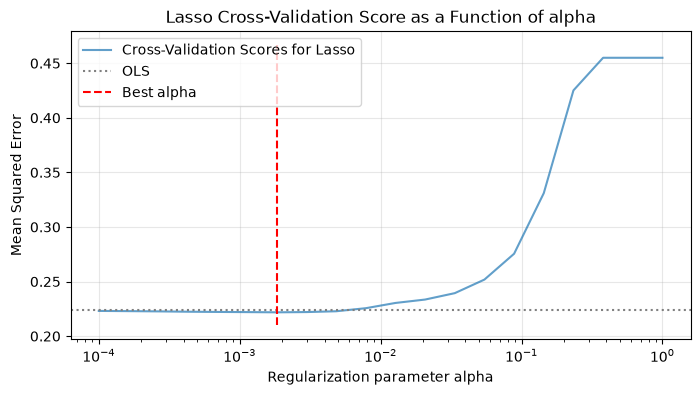

In [42]:
# Plot: Lasso CV error for each alpha
fig, ax = plt.subplots(figsize=(8, 4))

# CV error for each alpha that was tried
ax.plot(alphas_lasso, lasso_scores,
        alpha=0.7, label="Cross-Validation Scores for Lasso")
# OLS for comparison
ax.axhline(ols_cv_mse, color="grey", linestyle=":", label="OLS")
# The chosen alpha
ax.vlines(best_alpha_lasso, ax.get_ylim()[0], ax.get_ylim()[1], linestyle="--", color="red", label="Best alpha")

# Aesthetics
ax.set_xscale("log")        
ax.set_xlabel("Regularization parameter alpha")
ax.set_ylabel("Mean Squared Error")
ax.set_title("Lasso Cross-Validation Score as a Function of alpha")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

In [43]:
# Fit Lasso with the best alpha on all training households. Which features did it drop?
lasso = Pipeline([
    ("prep", make_preprocessor(features)),                      
    ("model", Lasso(alpha=best_alpha_lasso, max_iter=10000)), # Lasso with the chosen penalty
])
lasso.fit(X_train, y_train)                                      
lasso_coefs = pd.Series(lasso.named_steps["model"].coef_,
                        index=lasso.named_steps["prep"].get_feature_names_out())   
zero = lasso_coefs[lasso_coefs == 0].index.tolist()     # features with coefficient exactly 0

print(f"coefficients set to 0: {len(zero)} of {len(features)}")
print(zero)      # names of the dropped features
top_lasso = lasso_coefs.abs().sort_values(ascending=False).index[:10]   # 10 largest Lasso coefficients (by size)
display(lasso_coefs.loc[top_lasso].round(3))                           

coefficients set to 0: 17 of 92
['hr0615', 'hr0621', 'hhage', 'hr0609', 'hr0620', 'hr0632', 'hr0633', 'hr0635', 'hhmalemarr', 'hheduc2', 'hhsector1', 'se2_126_127', 'se2_117', 'se2_13_15', 'se5_110', 'hheduc_missing', 'se2_110']


hhsize        -0.525
hhsize2        0.277
hr0619         0.145
hr0627         0.094
pcfloor        0.068
se2_122_123   -0.061
hr0625         0.060
fcook          0.058
hr0616         0.057
hr0623         0.054
dtype: float64

#### Comparison of OLS, Ridge and Lasso (cross-validation)

In [44]:
# Compare the CV errors of the three models
cv_results = pd.DataFrame({
    "Model":  ["OLS", "Ridge", "Lasso"],  
    "alpha":  [0, best_alpha_ridge, best_alpha_lasso],   # chosen penalty (OLS = no penalty)
    "CV MSE": [ols_cv_mse, best_score_ridge, best_score_lasso],  # average CV error
}).set_index("Model").sort_values("CV MSE")     # lowest error first
cv_results["CV RMSE"] = np.sqrt(cv_results["CV MSE"])      # error in log-consumption units

display(cv_results.round(5)) # 5 decimals                                     

,alpha,CV MSE,CV RMSE
Model,,,
Lasso,0.00183,0.22182,0.47098
Ridge,12.74275,0.22275,0.47196
OLS,0.00000,0.22349,0.47275


**Result:**

All three models have almost the same CV error. Lasso has 0.2218 (alpha 0.0018), Ridge 0.2228 (alpha 12.7) and OLS 0.2235. In log consumption, this is an RMSE of about 0.47 for all three.

The differences between the models (at most 0.002) are much smaller than the differences between the folds. For OLS, the error goes from 0.203 to 0.237 depending on the fold.

Compared to set A, the penalty does a bit more. The best alphas are larger (Ridge 12.7 vs. 6.2, Lasso 0.0018 vs. 0.0007), and Lasso sets 17 of 92 coefficients to 0 (set A: 3 of 53). With more features, more of them carry the same information. For example, Lasso drops the car dummy (se2_126_127) but keeps the number of cars (hr0625). It also drops the number of rice huskers (hr0633), one of the pair with opposite signs in OLS.

But the gain is still very small. We have 4,090 training households and 92 features, about 44 households per feature, so OLS does not overfit much.

With the MSE, the three models are almost tied, so we cannot choose between them yet.

### 7. CV recall at the quota (the race metric)

In [45]:
# Targeting metrics for one validation fold
def targeting_metrics(val, score, name, k):
    selected = select_by_quota(val, score, higher_is_poorer=False)   # lowest predicted consumption gets the transfer
    poor = val["poor"].astype(int)   # true label: 1 = poor
    return {
        "model": name,
        "fold": k,
        "recall": recall_at_quota(val, selected),  # poor selected / all poor (main metric)
        "precision": poor[selected == 1].mean(),   # share of poor among the selected households
        "accuracy": (selected == poor).mean(),   # correct decisions / all households
        "roc_auc": roc_auc_score(poor, -val[score]),  # ranking quality over all households; minus, because low consumption = poor
        "within_auc": within_village_auc(val, score, higher_is_poorer=False),  # only pairs in the same village
    }

In [46]:
# The three models with their chosen alpha
models = {
    "OLS":   Pipeline([("prep", make_preprocessor(features, drop_first=True)), ("model", LinearRegression())]),
    "Ridge": Pipeline([("prep", make_preprocessor(features)), ("model", Ridge(alpha=best_alpha_ridge))]),
    "Lasso": Pipeline([("prep", make_preprocessor(features)), ("model", Lasso(alpha=best_alpha_lasso, max_iter=10000))]),
}
metrics = ["recall", "precision", "accuracy", "roc_auc", "within_auc"]  
references = ["Government formula", "Random", "Perfect ranking"]        
rng = np.random.default_rng(SEED)                                       

rows = []    # one row per model and fold
for k, (train_idx, val_idx) in enumerate(cv.split()):  # same 5 village folds as before
    val = train.iloc[val_idx].copy()    # the validation villages (whole villages)
    for name, model in models.items():
        model.fit(X_train.iloc[train_idx], y_train.iloc[train_idx])   # learn on the other 4 folds (preprocessing too)
        val[name] = model.predict(X_train.iloc[val_idx])   # predicted log consumption in fold k
        rows.append(targeting_metrics(val, name, name, k))
    rows.append(targeting_metrics(val, "pcexppred", "Government formula", k))   # reference: the government's formula
    rows.append(targeting_metrics(val, "LOGCONSUMPTION", "Perfect ranking", k))   # ceiling: ranking by the true consumption

    random_runs = []   # floor: 100 random rankings, then the average
    for r in range(100):
        val["Random"] = rng.random(len(val))  # a random score for every household
        random_runs.append(targeting_metrics(val, "Random", "Random", k))
    random_row = pd.DataFrame(random_runs)[metrics].mean().to_dict()   # average over the 100 random rankings
    random_row["model"] = "Random"
    random_row["fold"] = k
    rows.append(random_row)

fold_results = pd.DataFrame(rows)                                  

In [47]:
# Recall in every fold
display(fold_results.pivot(index="fold", columns="model", values="recall").round(3))

# Mean and standard deviation across the 5 folds, best recall first
summary = fold_results.groupby("model")[metrics].agg(["mean", "std"])
summary = summary.sort_values(("recall", "mean"), ascending=False)   # sort by mean recall
display(summary.round(3))

model,Government formula,Lasso,OLS,Perfect ranking,Random,Ridge
fold,,,,,,
0,0.559,0.605,0.582,0.716,0.367,0.602
1,0.544,0.579,0.588,0.682,0.374,0.588
2,0.548,0.548,0.548,0.664,0.352,0.551
3,0.552,0.587,0.583,0.729,0.383,0.583
4,0.498,0.534,0.523,0.639,0.341,0.527


recall        precision        accuracy        roc_auc  \
                     mean    std      mean    std     mean    std    mean   
model                                                                       
Perfect ranking     0.686  0.037     0.769  0.033    0.811  0.013   0.993   
Lasso               0.571  0.029     0.640  0.038    0.728  0.016   0.831   
Ridge               0.570  0.030     0.640  0.043    0.728  0.016   0.829   
OLS                 0.565  0.028     0.633  0.040    0.724  0.012   0.828   
Government formula  0.540  0.024     0.606  0.038    0.706  0.013   0.795   
Random              0.364  0.017     0.408  0.020    0.578  0.012   0.501   

                          within_auc         
                      std       mean    std  
model                                        
Perfect ranking     0.002      1.000  0.000  
Lasso               0.018      0.834  0.015  
Ridge               0.019      0.831  0.015  
OLS                 0.018      0.828  0.014  
Government formula  0.026      0.777  0.023  
Random              0.001      0.500  0.002

**Result:**

OLS, Ridge and Lasso reach between 56.5% and 57.1% recall at the quota. This means that out of 100 poor households, they find about 57. The government formula finds about 54, a random ranking about 36, and a perfect ranking about 69. Even the perfect ranking cannot reach 100%, because in poorer villages there are more poor households than transfers.

The recall of all models goes up and down together from fold to fold, because some villages are harder than others. So we compare the models fold by fold, on the same villages. Ridge beats the government formula in all 5 folds, and OLS and Lasso in 4 of 5 (in fold 2 they are equal). Their ranking within the villages is also clearly better (within-village AUC 0.83 vs. 0.78).

The gain is small, about 2.5 points for OLS, but fairly consistent. We check it again in section 10.

### 8. Elastic net 

In [48]:
# Elastic net
alphas_enet = np.logspace(-4, 0, 15)   
l1_ratios = [0.1, 0.5, 0.9]       # mix of the two penalties: 1 = only Lasso, 0 = only Ridge

enet_scores = {}    # for each l1_ratio: a list with the CV MSE of every alpha
for l1 in l1_ratios:   # try each mix
    enet_scores[l1] = []
    for alpha in alphas_enet: # try each alpha
        enet_model = Pipeline([
            ("prep", make_preprocessor(features)),
            ("model", ElasticNet(alpha=alpha, l1_ratio=l1, max_iter=10000)),
        ])
        cv_score = cross_val_score(enet_model, X_train, y_train, cv=cv,
                                   scoring="neg_mean_squared_error")  
        enet_scores[l1].append(-np.mean(cv_score))                   

enet_table = pd.DataFrame(enet_scores, index=alphas_enet)   # rows: alpha, columns: l1_ratio
best_l1_enet = enet_table.min().idxmin()   # l1_ratio with the lowest CV error
best_alpha_enet = enet_table[best_l1_enet].idxmin()   # the best alpha for that l1_ratio
best_score_enet = enet_table.min().min()    # that lowest CV error

print(f"Best l1_ratio: {best_l1_enet} | best alpha: {best_alpha_enet:.4f}")
print(f"Elastic Net CV MSE: {best_score_enet:.5f} | OLS CV MSE: {ols_cv_mse:.5f}")

Best l1_ratio: 0.9 | best alpha: 0.0027
Elastic Net CV MSE: 0.22192 | OLS CV MSE: 0.22349


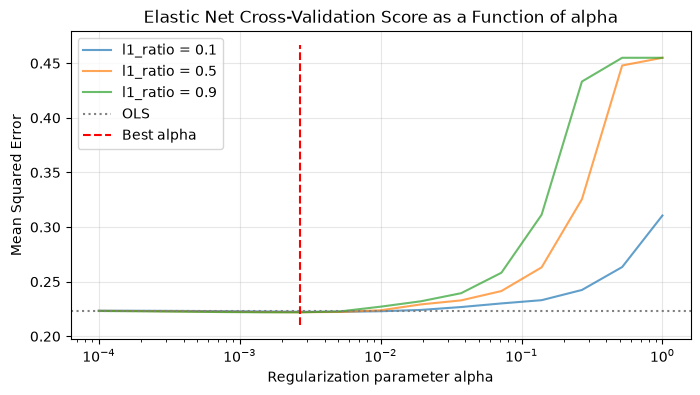

In [49]:
# Plot: Elastic Net CV error for each alpha
fig, ax = plt.subplots(figsize=(8, 4))

# CV error for each alpha, one line for each mix of the penalties
for l1 in l1_ratios:
    ax.plot(alphas_enet, enet_table[l1], alpha=0.7, label=f"l1_ratio = {l1}")
# OLS for comparison
ax.axhline(ols_cv_mse, color="grey", linestyle=":", label="OLS")
# The chosen alpha
ax.vlines(best_alpha_enet, ax.get_ylim()[0], ax.get_ylim()[1], linestyle="--", color="red", label="Best alpha")

# Aesthetics
ax.set_xscale("log")  
ax.set_xlabel("Regularization parameter alpha")
ax.set_ylabel("Mean Squared Error")
ax.set_title("Elastic Net Cross-Validation Score as a Function of alpha")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

In [50]:
# Fit Elastic Net with the best alpha and l1_ratio on all training households
enet = Pipeline([
    ("prep", make_preprocessor(features)),
    ("model", ElasticNet(alpha=best_alpha_enet, l1_ratio=best_l1_enet, max_iter=10000)),
])
enet.fit(X_train, y_train)                                      
enet_coefs = pd.Series(enet.named_steps["model"].coef_,
                       index=enet.named_steps["prep"].get_feature_names_out())   
zero_enet = enet_coefs[enet_coefs == 0].index.tolist()    # features with coefficient exactly 0

print(f"coefficients set to 0: {len(zero_enet)} of {len(features)}")
print(zero_enet)     # names of the dropped features

compare_enet = pd.DataFrame({"OLS": ols_coefs, "Lasso": lasso_coefs, "Elastic Net": enet_coefs})   
display(compare_enet.loc[top].round(3))                      

coefficients set to 0: 18 of 92
['hr0612', 'hr0615', 'hr0621', 'hhage', 'hr0620', 'hr0632', 'hr0633', 'hr0635', 'hhmale', 'hhmarried', 'hheduc2', 'hhsector1', 'se2_126_127', 'se2_117', 'se2_13_15', 'se5_110', 'hheduc_missing', 'se2_110']


,OLS,Lasso,Elastic Net
hhsize,-0.617,-0.525,-0.496
hhsize2,0.350,0.277,0.253
hr0619,0.165,0.145,0.137
hr0627,0.110,0.094,0.089
se2_132_133,0.082,0.013,0.012
se2_122_123,-0.077,-0.061,-0.056
hr0616,0.077,0.057,0.051
se2_118,0.073,0.030,0.030
se2_128,0.071,0.039,0.030
hr0633,-0.069,-0.000,-0.000


In [51]:
# Recall at the quota for Elastic Net
enet_rows = []                                                    
for k, (train_idx, val_idx) in enumerate(cv.split()):            
    val = train.iloc[val_idx].copy()                            
    enet_fold = Pipeline([
        ("prep", make_preprocessor(features)),
        ("model", ElasticNet(alpha=best_alpha_enet, l1_ratio=best_l1_enet, max_iter=10000)),
    ])
    enet_fold.fit(X_train.iloc[train_idx], y_train.iloc[train_idx])   # learn on the other 4 folds
    val["Elastic Net"] = enet_fold.predict(X_train.iloc[val_idx])   # predicted log consumption in fold k
    enet_rows.append(targeting_metrics(val, "Elastic Net", "Elastic Net", k))

fold_results_all = pd.concat([fold_results, pd.DataFrame(enet_rows)], ignore_index=True)   

# Mean and standard deviation across the 5 folds
summary_all = fold_results_all.groupby("model")[metrics].agg(["mean", "std"])
summary_all = summary_all.sort_values(("recall", "mean"), ascending=False)
display(summary_all.round(3))

recall        precision        accuracy        roc_auc  \
                     mean    std      mean    std     mean    std    mean   
model                                                                       
Perfect ranking     0.686  0.037     0.769  0.033    0.811  0.013   0.993   
Lasso               0.571  0.029     0.640  0.038    0.728  0.016   0.831   
Ridge               0.570  0.030     0.640  0.043    0.728  0.016   0.829   
Elastic Net         0.569  0.031     0.638  0.041    0.727  0.018   0.831   
OLS                 0.565  0.028     0.633  0.040    0.724  0.012   0.828   
Government formula  0.540  0.024     0.606  0.038    0.706  0.013   0.795   
Random              0.364  0.017     0.408  0.020    0.578  0.012   0.501   

                          within_auc         
                      std       mean    std  
model                                        
Perfect ranking     0.002      1.000  0.000  
Lasso               0.018      0.834  0.015  
Ridge               0.019      0.831  0.015  
Elastic Net         0.018      0.834  0.018  
OLS                 0.018      0.828  0.014  
Government formula  0.026      0.777  0.023  
Random              0.001      0.500  0.002

**Result:**

The best Elastic Net is almost pure Lasso (l1_ratio 0.9, alpha 0.0027). It has almost the same error as Lasso (MSE 0.2219 vs. 0.2218) and sets 18 of 92 coefficients to 0. 15 of them are the same as in Lasso.

The differences show how Lasso-type models choose between features that are similar. Lasso drops "male and married" (hhmalemarr) and keeps "male" (hhmale) and "married" (hhmarried). Elastic Net does the opposite. Both choices give almost the same predictions.

On the plot, the more Lasso is in the mix, the earlier the error goes up, because more coefficients become 0. With a large alpha, the error reaches 0.455: all coefficients are 0 and the model only predicts the mean.

Recall at the quota is 56.9%, between OLS and Lasso. So mixing the penalties does not help either. With the simplicity rule (see section 10), we still prefer OLS.

### 9. Boosting regressor

In [61]:
# Boosting, set B
features_boost = SET_B    
X_train_boost = train[features_boost].copy()   
num_cols = [c for c in features_boost if c != "kabu"] 
X_train_boost[num_cols] = X_train_boost[num_cols].astype(float)  

boost = Pipeline([
    ("prep", make_preprocessor(features_boost, scale=False)),  
    ("model", HistGradientBoostingRegressor(early_stopping=False, random_state=SEED)), 
])


param_distributions = {
    "model__learning_rate": [0.02, 0.05, 0.1],    
    "model__max_iter": [100, 200, 400, 800],
    "model__max_depth": [2, 3, 4, 5],             
    "model__min_samples_leaf": [20, 50, 100],    
    "model__l2_regularization": [0, 0.1, 1],   
}

search = RandomizedSearchCV(                          
    boost, param_distributions=param_distributions,
    n_iter=40,       
    scoring="neg_mean_squared_error",                  
    cv=cv,    
    random_state=SEED,                               
    return_train_score=True,    # keep the training error (to see overfitting)
    n_jobs=-1,  
)
search.fit(X_train_boost, y_train)   # tries all 40, then refits the best on all training households

best_params_boost = search.best_params_     # the best settings
best_score_boost = -search.best_score_      # their CV MSE (flip the sign)
print("Best settings:", best_params_boost)
print(f"Boosting CV MSE: {best_score_boost:.5f} | OLS CV MSE: {ols_cv_mse:.5f}")

Best settings: {'model__min_samples_leaf': 100, 'model__max_iter': 800, 'model__max_depth': 2, 'model__learning_rate': 0.05, 'model__l2_regularization': 0.1}
Boosting CV MSE: 0.21062 | OLS CV MSE: 0.22349


In [53]:
# The 5 best combinations
results_boost = pd.DataFrame(search.cv_results_)     # one row per combination that was tried
results_boost["CV MSE"] = -results_boost["mean_test_score"]  # flip the sign
results_boost["CV MSE std"] = results_boost["std_test_score"]    # spread across the 5 folds
results_boost["train MSE"] = -results_boost["mean_train_score"]  # error on the data the model learned from

show = ["param_model__learning_rate", "param_model__max_iter", "param_model__max_depth",
        "param_model__min_samples_leaf", "param_model__l2_regularization",
        "CV MSE", "CV MSE std", "train MSE"]
display(results_boost.sort_values("CV MSE")[show].head(5).round(4))

,param_model__learning_rate,param_model__max_iter,param_model__max_depth,param_model__min_samples_leaf,param_model__l2_regularization,CV MSE,CV MSE std,train MSE
19,0.05,800,2,100,0.1,0.2106,0.0126,0.1761
8,0.10,200,2,50,1.0,0.2112,0.0126,0.1827
7,0.02,800,3,50,0.1,0.2114,0.0117,0.1667
29,0.10,400,2,20,0.0,0.2121,0.0126,0.1627
37,0.05,400,2,100,0.0,0.2123,0.0136,0.1889


In [ ]:
# Check: the same boosting (same settings), but without the village-level columns
boost_nv = Pipeline([
    ("prep", make_preprocessor(features, scale=False)),    
    ("model", HistGradientBoostingRegressor(early_stopping=False, random_state=SEED)),
])
boost_nv.set_params(**best_params_boost)   # same settings as the best boosting above
cv_score = cross_val_score(boost_nv, X_train, y_train, cv=cv,
                           scoring="neg_mean_squared_error") 
best_score_boost_nv = -np.mean(cv_score)      

print(f"Boosting with village columns:    CV MSE {best_score_boost:.5f}")
print(f"Boosting without village columns: CV MSE {best_score_boost_nv:.5f}")
print(f"OLS (no village columns):         CV MSE {ols_cv_mse:.5f}")

Boosting with village columns:    CV MSE 0.21062
Boosting without village columns: CV MSE 0.21845
OLS (no village columns):         CV MSE 0.22349


In [55]:
# Recall at the quota for boosting, with and without the village-level columns
boost_rows = []     # one row per model and fold
for k, (train_idx, val_idx) in enumerate(cv.split()):   
    val = train.iloc[val_idx].copy()    # the validation villages

    boost_fold = Pipeline([    # with the village-level columns
        ("prep", make_preprocessor(features_boost, scale=False)),
        ("model", HistGradientBoostingRegressor(early_stopping=False, random_state=SEED)),
    ])
    boost_fold.set_params(**best_params_boost)     # use the best settings from the search
    boost_fold.fit(X_train_boost.iloc[train_idx], y_train.iloc[train_idx])    # learn on the other 4 folds
    val["Boosting"] = boost_fold.predict(X_train_boost.iloc[val_idx])     # predicted log consumption in fold k
    boost_rows.append(targeting_metrics(val, "Boosting", "Boosting", k))

    boost_nv_fold = Pipeline([   # without the village-level columns
        ("prep", make_preprocessor(features, scale=False)),
        ("model", HistGradientBoostingRegressor(early_stopping=False, random_state=SEED)),
    ])
    boost_nv_fold.set_params(**best_params_boost)             
    boost_nv_fold.fit(X_train.iloc[train_idx], y_train.iloc[train_idx])
    val["Boosting (no village)"] = boost_nv_fold.predict(X_train.iloc[val_idx])
    boost_rows.append(targeting_metrics(val, "Boosting (no village)", "Boosting (no village)", k))

fold_results_boost = pd.concat([fold_results_all, pd.DataFrame(boost_rows)], ignore_index=True)   # all models so far

# Recall in every fold
display(fold_results_boost.pivot(index="fold", columns="model", values="recall").round(3))

# Mean and sd
summary_boost = fold_results_boost.groupby("model")[metrics].agg(["mean", "std"])
summary_boost = summary_boost.sort_values(("recall", "mean"), ascending=False)
display(summary_boost.round(3))

candidates = summary_boost.drop(index=references)   # reference rows are not candidates
best_mean = candidates[("recall", "mean")].iloc[0]
best_std = candidates[("recall", "std")].iloc[0]
within = candidates.index[candidates[("recall", "mean")] >= best_mean - best_std].tolist()
print(f"best mean recall: {best_mean:.3f} (std {best_std:.3f})")
print("candidates within one std of the best:", within)

model,Boosting,Boosting (no village),Elastic Net,Government formula,Lasso,OLS,Perfect ranking,Random,Ridge
fold,,,,,,,,,
0,0.565,0.579,0.609,0.559,0.605,0.582,0.716,0.367,0.602
1,0.591,0.585,0.579,0.544,0.579,0.588,0.682,0.374,0.588
2,0.542,0.542,0.545,0.548,0.548,0.548,0.664,0.352,0.551
3,0.618,0.594,0.583,0.552,0.587,0.583,0.729,0.383,0.583
4,0.523,0.505,0.531,0.498,0.534,0.523,0.639,0.341,0.527


recall        precision        accuracy        roc_auc  \
                        mean    std      mean    std     mean    std    mean   
model                                                                          
Perfect ranking        0.686  0.037     0.769  0.033    0.811  0.013   0.993   
Lasso                  0.571  0.029     0.640  0.038    0.728  0.016   0.831   
Ridge                  0.570  0.030     0.640  0.043    0.728  0.016   0.829   
Elastic Net            0.569  0.031     0.638  0.041    0.727  0.018   0.831   
Boosting               0.568  0.038     0.636  0.033    0.726  0.011   0.843   
OLS                    0.565  0.028     0.633  0.040    0.724  0.012   0.828   
Boosting (no village)  0.561  0.037     0.628  0.041    0.721  0.012   0.834   
Government formula     0.540  0.024     0.606  0.038    0.706  0.013   0.795   
Random                 0.364  0.017     0.408  0.020    0.578  0.012   0.501   

                             within_auc         
                         std       mean    std  
model                                           
Perfect ranking        0.002      1.000  0.000  
Lasso                  0.018      0.834  0.015  
Ridge                  0.019      0.831  0.015  
Elastic Net            0.018      0.834  0.018  
Boosting               0.012      0.830  0.016  
OLS                    0.018      0.828  0.014  
Boosting (no village)  0.015      0.828  0.019  
Government formula     0.026      0.777  0.023  
Random                 0.001      0.500  0.002

best mean recall: 0.571 (std 0.029)
candidates within one std of the best: ['Lasso', 'Ridge', 'Elastic Net', 'Boosting', 'OLS', 'Boosting (no village)']


**Result:**

The best boosting model uses small trees (depth 2), 800 trees, a learning rate of 0.05 and at least 100 households per leaf. 800 is the largest number of trees in our grid, so more trees might help a little. Because boosting does not win the race (section 10), we did not extend the grid.

Its CV error is lower than for OLS (MSE 0.211 vs. 0.224), and the training MSE is 0.176, so it overfits only a little. This CV error is a bit too optimistic, because we picked the best of 40 settings on the same folds. OLS has nothing to tune, so it does not get this bonus.

But recall at the quota is 56.8%, the same level as the linear models (OLS 56.5%, Lasso 57.1%). Boosting has the highest ROC AUC over all households (0.843), because the village-level columns help to predict which villages are richer. But inside a village these columns are the same for everyone. The within-village AUC shows this: boosting has 0.830, almost the same as OLS (0.828) and Lasso (0.834).

Without the village-level columns, boosting gets an MSE of 0.219 and a recall of 56.1%. So its MSE is still a bit lower than for OLS, but it finds fewer poor households. A lower MSE does not mean better targeting.

### 10. Regression winner

In [56]:
# All models of the regression race in one table
cv_mse = pd.Series({"OLS": ols_cv_mse, "Ridge": best_score_ridge, "Lasso": best_score_lasso,
                    "Elastic Net": best_score_enet, "Boosting": best_score_boost,
                    "Boosting (no village)": best_score_boost_nv})   # CV MSE (the tuning score)

final = pd.DataFrame({
    "CV MSE": cv_mse,                                       
    "recall mean": summary_boost[("recall", "mean")],   # main metric
    "recall std": summary_boost[("recall", "std")],         
    "ROC AUC": summary_boost[("roc_auc", "mean")],     # ranking quality over all households
    "within AUC": summary_boost[("within_auc", "mean")],   # ranking quality inside the villages
}).sort_values("recall mean", ascending=False)

# Share of the possible improvement: (recall - random) / (perfect - random)
random_recall = final.loc["Random", "recall mean"]
perfect_recall = final.loc["Perfect ranking", "recall mean"]
final["share of possible gain"] = (final["recall mean"] - random_recall) / (perfect_recall - random_recall)
display(final.round(3))

simplicity_order = ["OLS", "Ridge", "Lasso", "Elastic Net", "Boosting (no village)", "Boosting"]   # simplest first
candidates = final.drop(index=references)                            
best = candidates["recall mean"].idxmax()     # model with the best mean recall
threshold = candidates.loc[best, "recall mean"] - candidates.loc[best, "recall std"]
within = candidates.index[candidates["recall mean"] >= threshold].tolist()
winner = [m for m in simplicity_order if m in within][0]   # the simplest of these

print(f"best mean recall: {best} ({candidates.loc[best, 'recall mean']:.3f}, std {candidates.loc[best, 'recall std']:.3f})")
print("within one std of the best:", within)
print("regression winner:", winner)

# Stricter check: one standard error (std / square root of the 5 folds) instead of one std
threshold_se = candidates.loc[best, "recall mean"] - candidates.loc[best, "recall std"] / np.sqrt(5)
within_se = candidates.index[candidates["recall mean"] >= threshold_se].tolist()
winner_se = [m for m in simplicity_order if m in within_se][0]  # the simplest of these
print("within one standard error:", within_se, "| winner:", winner_se)

,CV MSE,recall mean,recall std,ROC AUC,within AUC,share of possible gain
Perfect ranking,NaN,0.686,0.037,0.993,1.000,1.000
Lasso,0.222,0.571,0.029,0.831,0.834,0.642
Ridge,0.223,0.570,0.030,0.829,0.831,0.641
Elastic Net,0.222,0.569,0.031,0.831,0.834,0.638
Boosting,0.211,0.568,0.038,0.843,0.830,0.633
OLS,0.223,0.565,0.028,0.828,0.828,0.624
Boosting (no village),0.218,0.561,0.037,0.834,0.828,0.611
Government formula,NaN,0.540,0.024,0.795,0.777,0.547
Random,NaN,0.364,0.017,0.501,0.500,0.000


best mean recall: Lasso (0.571, std 0.029)
within one std of the best: ['Lasso', 'Ridge', 'Elastic Net', 'Boosting', 'OLS', 'Boosting (no village)']
regression winner: OLS
within one standard error: ['Lasso', 'Ridge', 'Elastic Net', 'Boosting', 'OLS', 'Boosting (no village)'] | winner: OLS


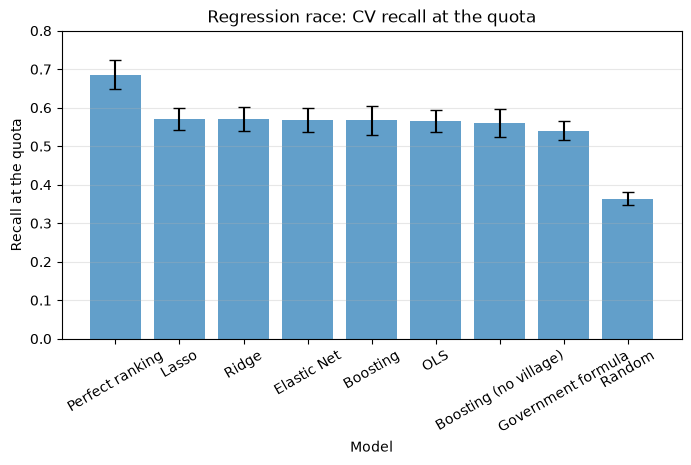

In [57]:
# Plot
fig, ax = plt.subplots(figsize=(8, 4))

ax.bar(final.index, final["recall mean"], yerr=final["recall std"],  
       capsize=4, alpha=0.7)

# Aesthetics
ax.set_ylim(0, 0.8)   
ax.set_xlabel("Model")
ax.set_ylabel("Recall at the quota")
ax.set_title("Regression race: CV recall at the quota")
ax.grid(axis="y", alpha=0.3)
ax.tick_params(axis="x", rotation=30)   
plt.show()

**Result:**

All six models reach almost the same recall at the quota, between 56.1% (boosting without village columns) and 57.1% (Lasso). Lasso has the best mean, but its standard deviation across the folds is 2.9 points, so all six models are within one standard deviation of it.

With the simplicity rule, OLS is the winner of the regression race. With the stricter rule (one standard error instead of one standard deviation), OLS also wins.

OLS beats the government formula in 4 of the 5 folds and is equal in fold 2. On average it is 2.5 points better (section 7). This gain is small but fairly consistent. The final test has to confirm it in new villages.

Between a random ranking (36.4%) and a perfect ranking (68.6%), OLS reaches 62% of the possible improvement, Lasso 64%. The government formula reaches 55%.

### 11. Conclusion 

This notebook shows that the extra information in set B (13 visible assets and 26 asset counts) helps to predict consumption, but not to find the poor households. In comparison to set A, the CV MSE goes down by about 5% for every model (OLS: 0.234 → 0.223), but recall at the quota goes up by less than 1 point (OLS: 56.1% → 56.5%). This gain is much smaller than the spread between the folds (about 3 points), so it could just be noise. With the simplicity rule, OLS is the winner again, and it still finds about 2 more poor households out of 100 than the government formula (56.5% vs. 54.0%). So we keep set A for the final model: set B needs more questions per household and some assets, like jewelry, are easy to hide, but it does not clearly choose the right households more often.

